# Đồ án IE313 – Phân tích nhu cầu thuê xe đạp công cộng tại Seoul

Notebook duy nhất của nhóm, chạy từ đầu đến cuối bằng *Run All*. Dữ liệu: *Seoul Bike Sharing Demand*, UCI Machine Learning Repository [DOI 10.24432/C5F62R].

| Phần | Nội dung | Đầu vào → đầu ra |
|---|---|---|
| A | Kiểm tra và chuẩn bị dữ liệu | `Nhom23_Data_raw.csv` → `Nhom23_Data_clean.csv` |
| B | Phân tích thăm dò, trực quan hóa, ANOVA | `Nhom23_Data_clean.csv` → `figures/eda/*.png`, `descriptive_statistics.xlsx`, `anova_result.xlsx` |
| C | Xây dựng và đánh giá mô hình hồi quy (đơn, đa biến, Ridge) | `df_run` → `figures/model/*.png`, `model_comparison.xlsx` |

**Cách chạy lại:** đặt notebook cùng thư mục với `Nhom23_Data_raw.csv`, rồi chọn *Run All*. Thư viện cần có: pandas, numpy, scipy, matplotlib, seaborn, openpyxl, scikit-learn.

# Phần A. Chuẩn bị dữ liệu
Nguồn: UCI Machine Learning Repository, DOI: 10.24432/C5F62R. Tệp gốc được giữ nguyên; các thay đổi được ghi ở những ô mã bên dưới.

In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path.cwd()
raw_path = data_dir / 'Nhom23_Data_raw.csv'
clean_path = data_dir / 'Nhom23_Data_clean.csv'
df = pd.read_csv(raw_path, encoding='cp1252')  # ký tự ° trong tiêu đề cột
print('Kích thước:', df.shape)
display(df.head())
display(df.dtypes.to_frame('Kiểu dữ liệu'))

Kích thước: (8760, 14)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


,Kiểu dữ liệu
Date,str
Rented Bike Count,int64
Hour,int64
Temperature(°C),float64
Humidity(%),int64
Wind speed (m/s),float64
Visibility (10m),int64
Dew point temperature(°C),float64
Solar Radiation (MJ/m2),float64
Rainfall(mm),float64


In [2]:
print('Số ô khuyết:', int(df.isna().sum().sum()))

print('Số dòng trùng:', int(df.duplicated().sum()))

print('Cặp Date–Hour trùng:', int(df.duplicated(['Date', 'Hour']).sum()))

display(pd.DataFrame({'Kiểu dữ liệu': df.dtypes.astype(str), 'Số giá trị duy nhất': df.nunique(), 'Số ô khuyết': df.isna().sum()}))

display(df.select_dtypes(include='number').agg(['min', 'max']).T)

for col in ['Seasons', 'Holiday', 'Functioning Day']:
    print(col, df[col].value_counts().to_dict())
dates = pd.to_datetime(df['Date'], format='%d/%m/%Y', errors='raise')
assert len(df) == 8760 and len(df.columns) == 14
assert not df.isna().any().any() and not df.duplicated().any()
assert not df.duplicated(['Date', 'Hour']).any()
assert df.groupby('Date')['Hour'].nunique().eq(24).all()

print('Giai đoạn:', dates.min().date(), 'đến', dates.max().date())

Số ô khuyết: 0
Số dòng trùng: 0
Cặp Date–Hour trùng: 0


,Kiểu dữ liệu,Số giá trị duy nhất,Số ô khuyết
Date,str,365,0
Rented Bike Count,int64,2166,0
Hour,int64,24,0
Temperature(°C),float64,546,0
Humidity(%),int64,90,0
Wind speed (m/s),float64,65,0
Visibility (10m),int64,1789,0
Dew point temperature(°C),float64,556,0
Solar Radiation (MJ/m2),float64,345,0
Rainfall(mm),float64,61,0


,min,max
Rented Bike Count,0.0,3556.00
Hour,0.0,23.00
Temperature(°C),-17.8,39.40
Humidity(%),0.0,98.00
Wind speed (m/s),0.0,7.40
Visibility (10m),27.0,2000.00
Dew point temperature(°C),-30.6,27.20
Solar Radiation (MJ/m2),0.0,3.52
Rainfall(mm),0.0,35.00
Snowfall (cm),0.0,8.80


Seasons {'Spring': 2208, 'Summer': 2208, 'Autumn': 2184, 'Winter': 2160}
Holiday {'No Holiday': 8328, 'Holiday': 432}
Functioning Day {'Yes': 8465, 'No': 295}
Giai đoạn: 2017-12-01 đến 2018-11-30


## Kiểm tra giá trị 0 và giá trị lớn
Các giờ hệ thống không hoạt động có số lượt thuê bằng 0. Các giá trị thuê cao được kiểm tra bằng quy tắc IQR để nhận diện, không tự động xóa vì có thể phản ánh nhu cầu thực.

In [3]:
y = df['Rented Bike Count']
q1, q3 = y.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print('Số giờ không hoạt động:', int(df['Functioning Day'].eq('No').sum()))

print('Số giờ có 0 lượt thuê:', int(y.eq(0).sum()))

print('0 lượt thuê nhưng hệ thống hoạt động:', int((y.eq(0) & df['Functioning Day'].eq('Yes')).sum()))

print('Ngưỡng IQR phía trên:', upper, '; số giá trị vượt ngưỡng:', int(y.gt(upper).sum()))

Số giờ không hoạt động: 295
Số giờ có 0 lượt thuê: 295
0 lượt thuê nhưng hệ thống hoạt động: 0
Ngưỡng IQR phía trên: 2376.625 ; số giá trị vượt ngưỡng: 158


In [4]:
clean = df.copy()
clean['Date'] = dates.dt.strftime('%Y-%m-%d')
clean['Month'] = dates.dt.month
clean['DayOfWeek'] = dates.dt.dayofweek  # Thứ Hai=0, Chủ nhật=6
clean['IsWeekend'] = dates.dt.dayofweek.ge(5).astype(int)
assert clean.shape == (8760, 17)
assert clean['Date'].str.match(r'\d{4}-\d{2}-\d{2}').all()
clean.to_csv(clean_path, index=False, encoding='utf-8-sig')
print('Đã lưu:', clean_path.name, '; số dòng:', len(clean), '; số cột:', len(clean.columns))
print('Không xóa dòng, không điền giá trị, không loại điểm thuê cao.')

Đã lưu: Nhom23_Data_clean.csv ; số dòng: 8760 ; số cột: 17
Không xóa dòng, không điền giá trị, không loại điểm thuê cao.


# Phần B. Phân tích thăm dò và trực quan hóa dữ liệu

Phần này chỉ đọc **một file dữ liệu sạch dùng chung** (`Nhom23_Data_clean.csv`, do Phần A tạo ra từ file gốc của UCI) và không sửa file đó. Toàn bộ biểu đồ, bảng thống kê và kết quả ANOVA đều được tạo từ notebook này và lưu vào:

| Đầu ra | Nội dung |
|---|---|
| `figures/eda/*.png` | Quy trình phân tích (00), 8 hình EDA chính (01–08) và các hình phụ |
| `descriptive_statistics.xlsx` | Thống kê mô tả, groupby, pivot, tương quan, bảng chọn biến |
| `anova_result.xlsx` | Giả thuyết, F, p-value, kết luận và so sánh từng cặp mùa |

**Mục lục (Phần B):** 1. Thiết lập → 2. Nạp và kiểm tra dữ liệu → 3. Thống kê mô tả → 4. Phân phối và ngoại lệ → 5. Theo giờ → 6. Theo mùa và ngày lễ → 7. Nhiệt độ và mưa → 8. Tương quan → 9. ANOVA → 10. Chọn biến → 11. Xuất file → 12. Hình quy trình.

## 1. Thiết lập

Khai báo thư viện, hằng số, bảng màu và các hàm dùng chung. Quy ước định dạng số theo kiểu Việt Nam (dấu chấm ngăn hàng nghìn, dấu phẩy thập phân) để số liệu trên hình khớp với báo cáo.

In [5]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter
from scipy import stats

# ---- Tham số phân tích ---------------------------------------------------------------
ALPHA = 0.05                      # mức ý nghĩa thống kê
IQR_K = 1.5                       # hệ số ngưỡng ngoại lệ: Q3 + 1,5 x IQR (theo slide Bài 5)
TARGET = 'Rented Bike Count'      # biến mục tiêu: số lượt thuê xe mỗi giờ
SEASONS = ['Spring', 'Summer', 'Autumn', 'Winter']
SEASON_VI = {'Spring': 'Xuân', 'Summer': 'Hạ', 'Autumn': 'Thu', 'Winter': 'Đông'}

# ---- Tên cột (giữ nguyên như file sạch) ------------------------------------------------
TEMP, HUM, WIND = 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)'
VIS, DEW, SOLAR = 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)'
RAIN, SNOW = 'Rainfall(mm)', 'Snowfall (cm)'
LABEL_VI = {TARGET: 'Số lượt thuê', 'Hour': 'Giờ', TEMP: 'Nhiệt độ', HUM: 'Độ ẩm',
            WIND: 'Tốc độ gió', VIS: 'Tầm nhìn', DEW: 'Điểm sương', SOLAR: 'Bức xạ mặt trời',
            RAIN: 'Lượng mưa', SNOW: 'Lượng tuyết', 'IsWeekend': 'Cuối tuần'}

# ---- Đường dẫn -------------------------------------------------------------------------
DATA_PATH = clean_path          # tệp sạch do Phần A vừa xuất
FIG_DIR = Path('figures/eda')
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Dữ liệu:', DATA_PATH.resolve().name, '| Thư mục hình:', FIG_DIR)

Dữ liệu: Nhom23_Data_clean.csv | Thư mục hình: figures\eda


In [6]:
# ---- Bảng màu (xanh dương = nhóm/chuỗi chính, cam = nhóm so sánh) và kiểu chung của hình ------
BLUE, BLUE_LIGHT, BLUE_DARK, ORANGE = '#2a78d6', '#9ec5f4', '#184f95', '#eb6834'
INK, INK2, GRID, AXIS = '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7'
CMAP_DIV = LinearSegmentedColormap.from_list('div_xanh_do', [BLUE, '#f0efec', '#e34948'])   # tương quan
CMAP_SEQ = LinearSegmentedColormap.from_list('seq_xanh', ['#cde2fb', '#2a78d6', '#0d366b'])  # độ lớn

plt.rcParams.update({
    'figure.figsize': (7, 4.2), 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'text.color': INK, 'axes.titlecolor': INK, 'axes.titleweight': 'bold', 'axes.titlesize': 11.5,
    'axes.titlelocation': 'left', 'axes.labelsize': 10, 'font.size': 10,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False,
})


def vn_num(x, nd=0):
    """Định dạng số kiểu Việt Nam: 1.234,5."""
    return f'{x:,.{nd}f}'.replace(',', '#').replace('.', ',').replace('#', '.')


def vn_p(p):
    """p-value: scipy trả về 0,0 khi quá nhỏ nên hiển thị 'p < 0,001'."""
    return 'p < 0,001' if p < 0.001 else 'p = ' + vn_num(p, 3)


THOUSANDS = FuncFormatter(lambda v, _: vn_num(v))


def save_fig(fig, name):
    """Lưu hình PNG 200 dpi vào figures/eda rồi hiển thị."""
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches='tight', facecolor='white')
    plt.show()
    print('Đã lưu:', FIG_DIR / name)

## 2. Nạp và kiểm tra dữ liệu

Đọc file sạch (mã hóa `utf-8-sig` để giữ ký hiệu °C trong tên cột) và kiểm tra lại các thông số mà Phần A đã xuất.

**Phạm vi phân tích.** Có 295 giờ hệ thống ngừng hoạt động (`Functioning Day = No`) và cả 295 giờ này đều có 0 lượt thuê. Đó là thời gian hệ thống không phục vụ, không phản ánh nhu cầu thật của người dùng, nên các biểu đồ theo giờ, mùa, ngày lễ, nhiệt độ, mưa, ma trận tương quan và ANOVA đều dùng tập **`df_run`** (chỉ gồm giờ hoạt động). Thống kê mô tả vẫn trình bày cả hai phiên bản để đối chiếu. File dữ liệu sạch **không bị sửa**.

In [7]:
df_all = pd.read_csv(DATA_PATH, encoding='utf-8-sig', parse_dates=['Date'])

# Kiểm tra lại các thông số Phần A đã xuất
assert df_all.shape == (8760, 17), df_all.shape
assert not df_all.isna().any().any()
assert (df_all['Functioning Day'] == 'No').sum() == 295
assert df_all.loc[df_all['Functioning Day'] == 'No', TARGET].eq(0).all()

df_run = df_all[df_all['Functioning Day'] == 'Yes'].copy()     # tập dùng để phân tích
assert df_run[TARGET].min() > 0

print('Toàn bộ dữ liệu :', df_all.shape, '| giai đoạn', df_all['Date'].min().date(), '→', df_all['Date'].max().date())
print('Giờ hoạt động   :', df_run.shape)
display(df_all.head(3))

Toàn bộ dữ liệu : (8760, 17) | giai đoạn 2017-12-01 → 2018-11-30
Giờ hoạt động   : (8465, 17)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Month,DayOfWeek,IsWeekend
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,4,0
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,12,4,0
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,12,4,0


In [8]:
# Cỡ mẫu theo biến phân loại (đếm số giờ) – dùng để nêu cỡ nhóm trong báo cáo
cat_counts = pd.concat({c: df_all[c].value_counts() for c in ['Seasons', 'Holiday', 'Functioning Day']}, names=['Biến', 'Giá trị']).rename('Số giờ').to_frame()
display(cat_counts)
print('Số ngày lễ (Holiday):', df_all.loc[df_all['Holiday'] == 'Holiday', 'Date'].nunique(), 'ngày')

Số giờ
Biến            Giá trị           
Seasons         Spring        2208
                Summer        2208
                Autumn        2184
                Winter        2160
Holiday         No Holiday    8328
                Holiday        432
Functioning Day Yes           8465
                No             295

Số ngày lễ (Holiday): 18 ngày


## 3. Thống kê mô tả

Tính các đại lượng đã học ở Bài 5: hướng trung tâm (mean, median, mode), độ phân tán (range, Q1, Q3, IQR, std, hệ số biến thiên CV) và hình dáng phân phối (skewness, kurtosis). Kurtosis tính theo kiểu của pandas (Fisher): bằng 0 khi phân phối chuẩn. CV chỉ tính cho biến không âm (nhiệt độ và điểm sương có thể âm nên không tính CV).

In [9]:
def describe_ext(d, cols):
    """Bảng thống kê mô tả mở rộng cho các cột số của d."""
    x = d[cols]
    out = pd.DataFrame({
        'count': x.count(), 'mean': x.mean(), 'median': x.median(),
        'mode': x.apply(lambda s: s.mode().iloc[0]),
        'min': x.min(), 'max': x.max(), 'range': x.max() - x.min(), 'std': x.std(),
        'Q1': x.quantile(0.25), 'Q3': x.quantile(0.75),
    })
    out['IQR'] = out['Q3'] - out['Q1']
    out['CV (%)'] = np.where(x.min() >= 0, out['std'] / out['mean'] * 100, np.nan)
    out['skewness'] = x.skew()
    out['kurtosis'] = x.kurt()
    return out


NUM_COLS = [TARGET, 'Hour', TEMP, HUM, WIND, VIS, DEW, SOLAR, RAIN, SNOW]

desc_target = pd.concat({'Toàn bộ (8.760 giờ)': describe_ext(df_all, [TARGET]),
                         'Giờ hoạt động (8.465 giờ)': describe_ext(df_run, [TARGET])}).droplevel(1)
desc_run = describe_ext(df_run, NUM_COLS)
desc_all = describe_ext(df_all, NUM_COLS)

pd.options.display.float_format = '{:,.2f}'.format
display(desc_target)
display(desc_run)

,count,mean,median,mode,min,max,range,std,Q1,Q3,IQR,CV (%),skewness,kurtosis
Toàn bộ (8.760 giờ),8760,704.60,504.50,0,0,3556,3556,645.00,191.00,"1,065.25",874.25,91.54,1.15,0.85
Giờ hoạt động (8.465 giờ),8465,729.16,542.00,122,2,3556,3554,642.35,214.00,"1,084.00",870.00,88.10,1.14,0.82


,count,mean,median,mode,min,max,range,std,Q1,Q3,IQR,CV (%),skewness,kurtosis
Rented Bike Count,8465,729.16,542.00,122.00,2.00,"3,556.00","3,554.00",642.35,214.00,"1,084.00",870.00,88.10,1.14,0.82
Hour,8465,11.51,12.00,7.00,0.00,23.00,23.00,6.92,6.00,18.00,12.00,60.14,-0.00,-1.20
Temperature(°C),8465,12.77,13.50,19.10,-17.80,39.40,57.20,12.10,3.00,22.70,19.70,NaN,-0.17,-0.89
Humidity(%),8465,58.15,57.00,97.00,0.00,98.00,98.00,20.48,42.00,74.00,32.00,35.23,0.07,-0.81
Wind speed (m/s),8465,1.73,1.50,1.10,0.00,7.40,7.40,1.03,0.90,2.30,1.40,59.93,0.89,0.75
Visibility (10m),8465,"1,433.87","1,690.00","2,000.00",27.00,"2,000.00","1,973.00",609.05,935.00,"2,000.00","1,065.00",42.48,-0.70,-0.97
Dew point temperature(°C),8465,3.94,4.70,0.00,-30.60,27.20,57.80,13.24,-5.10,15.20,20.30,NaN,-0.34,-0.82
Solar Radiation (MJ/m2),8465,0.57,0.01,0.00,0.00,3.52,3.52,0.87,0.00,0.93,0.93,152.90,1.51,1.15
Rainfall(mm),8465,0.15,0.00,0.00,0.00,35.00,35.00,1.13,0.00,0.00,0.00,754.79,14.62,289.96
Snowfall (cm),8465,0.08,0.00,0.00,0.00,8.80,8.80,0.44,0.00,0.00,0.00,571.62,8.29,90.54


## 4. Phân phối và ngoại lệ của số lượt thuê xe

Histogram cho thấy hình dạng phân phối; boxplot cho thấy ngoại lệ theo quy tắc IQR (giá trị lớn hơn Q3 + 1,5 × IQR). Các giá trị ngoại lệ **không bị xóa** – ở phần dưới sẽ kiểm tra chúng rơi vào giờ nào, mùa nào.

In [10]:
y = df_run[TARGET]
q1, med, q3 = y.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
upper_fence = q3 + IQR_K * iqr
n_out = int((y > upper_fence).sum())
print(f'n = {len(y)} | mean = {y.mean():.1f} | median = {med:.1f} | Q1 = {q1:.1f} | Q3 = {q3:.1f} | IQR = {iqr:.1f}')
print(f'Ngưỡng ngoại lệ trên = {upper_fence:.1f} → {n_out} giờ ({n_out / len(y):.1%}); ngưỡng dưới âm nên không có ngoại lệ dưới')
print(f'Skewness = {y.skew():.2f} | kurtosis = {y.kurt():.2f}')

n = 8465 | mean = 729.2 | median = 542.0 | Q1 = 214.0 | Q3 = 1084.0 | IQR = 870.0
Ngưỡng ngoại lệ trên = 2389.0 → 152 giờ (1.8%); ngưỡng dưới âm nên không có ngoại lệ dưới
Skewness = 1.14 | kurtosis = 0.82


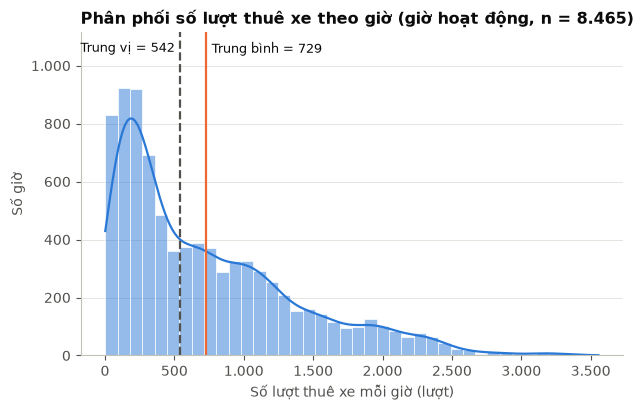

Đã lưu: figures\eda\01_phan_phoi_luot_thue.png


In [11]:
# Hình 1 – Histogram
fig, ax = plt.subplots()
sns.histplot(y, bins=40, kde=True, color=BLUE, edgecolor='white', linewidth=0.5,
             line_kws={'linewidth': 1.6}, ax=ax)
ax.axvline(y.mean(), color=ORANGE, lw=1.6)
ax.axvline(med, color=INK2, lw=1.6, ls='--')
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)                 # chừa khoảng trống phía trên cột để ghi nhãn
top = ax.get_ylim()[1]
ax.text(y.mean() + 40, top * 0.97, f'Trung bình = {vn_num(y.mean())}', ha='left', va='top', fontsize=9)
ax.text(med - 40, top * 0.97, f'Trung vị = {vn_num(med)}', ha='right', va='top', fontsize=9)
ax.set_title(f'Phân phối số lượt thuê xe theo giờ (giờ hoạt động, n = {vn_num(len(y))})')
ax.set_xlabel('Số lượt thuê xe mỗi giờ (lượt)')
ax.set_ylabel('Số giờ')
ax.xaxis.set_major_formatter(THOUSANDS)
ax.yaxis.set_major_formatter(THOUSANDS)
save_fig(fig, '01_phan_phoi_luot_thue.png')

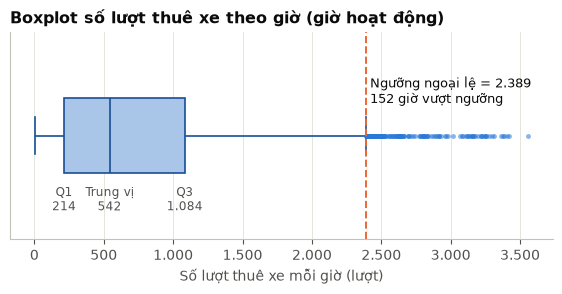

Đã lưu: figures\eda\02_boxplot_luot_thue.png


In [12]:
# Hình 2 – Boxplot và ngoại lệ
fig, ax = plt.subplots(figsize=(7, 2.7))
sns.boxplot(x=y, orient='h', color=BLUE_LIGHT, linecolor=BLUE_DARK, linewidth=1.2, width=0.45,
            flierprops={'marker': 'o', 'markerfacecolor': BLUE, 'markeredgecolor': 'none',
                        'markersize': 3.5, 'alpha': 0.55}, ax=ax)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.axvline(upper_fence, color=ORANGE, lw=1.4, ls='--')
ax.text(upper_fence + 30, -0.36, f'Ngưỡng ngoại lệ = {vn_num(upper_fence)}\n{n_out} giờ vượt ngưỡng',
        ha='left', va='top', fontsize=9)
for val, name, dy in [(q1, 'Q1', 0.30), (med, 'Trung vị', 0.30), (q3, 'Q3', 0.30)]:
    ax.text(val, dy, f'{name}\n{vn_num(val)}', ha='center', va='top', fontsize=8.5, color=INK2)
ax.set_title('Boxplot số lượt thuê xe theo giờ (giờ hoạt động)')
ax.set_xlabel('Số lượt thuê xe mỗi giờ (lượt)')
ax.set_yticks([])
ax.set_ylim(0.62, -0.62)
ax.xaxis.set_major_formatter(THOUSANDS)
save_fig(fig, '02_boxplot_luot_thue.png')

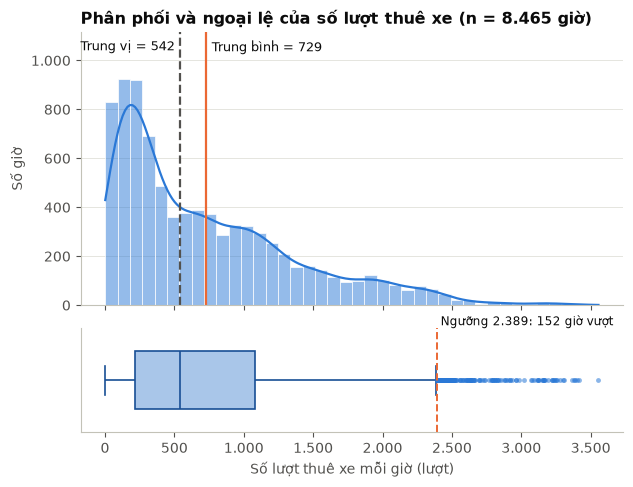

Đã lưu: figures\eda\01b_phan_phoi_va_boxplot.png


In [13]:
# Hình ghép 1+2 (dùng trong báo cáo để tiết kiệm chỗ): histogram phía trên, boxplot phía dưới, chung trục x
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 5.2), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1.15], 'hspace': 0.12})
sns.histplot(y, bins=40, kde=True, color=BLUE, edgecolor='white', linewidth=0.5,
             line_kws={'linewidth': 1.6}, ax=ax1)
ax1.axvline(y.mean(), color=ORANGE, lw=1.6)
ax1.axvline(med, color=INK2, lw=1.6, ls='--')
ax1.set_ylim(0, ax1.get_ylim()[1] * 1.15)
top = ax1.get_ylim()[1]
ax1.text(y.mean() + 40, top * 0.97, f'Trung bình = {vn_num(y.mean())}', ha='left', va='top', fontsize=9)
ax1.text(med - 40, top * 0.97, f'Trung vị = {vn_num(med)}', ha='right', va='top', fontsize=9)
ax1.set_title(f'Phân phối và ngoại lệ của số lượt thuê xe (n = {vn_num(len(y))} giờ)')
ax1.set_ylabel('Số giờ')
ax1.yaxis.set_major_formatter(THOUSANDS)
sns.boxplot(x=y, orient='h', color=BLUE_LIGHT, linecolor=BLUE_DARK, linewidth=1.2, width=0.55,
            flierprops={'marker': 'o', 'markerfacecolor': BLUE, 'markeredgecolor': 'none',
                        'markersize': 3.5, 'alpha': 0.55}, ax=ax2)
ax2.grid(axis='y', visible=False)
ax2.axvline(upper_fence, color=ORANGE, lw=1.4, ls='--')
ax2.text(upper_fence + 30, -0.62, f'Ngưỡng {vn_num(upper_fence)}: {n_out} giờ vượt', ha='left', va='top', fontsize=8.5)
ax2.set_yticks([])
ax2.set_xlabel('Số lượt thuê xe mỗi giờ (lượt)')
ax2.xaxis.set_major_formatter(THOUSANDS)
save_fig(fig, '01b_phan_phoi_va_boxplot.png')

**Các giá trị ngoại lệ rơi vào đâu?** Kiểm tra theo giờ, mùa và nhiệt độ để xem đây là nhu cầu thật hay lỗi đo.

In [14]:
outliers = df_run[df_run[TARGET] > upper_fence]
out_hour = outliers['Hour'].value_counts().sort_index().rename('Số giờ ngoại lệ').to_frame()
out_season = outliers['Seasons'].value_counts().reindex(SEASONS, fill_value=0).rename('Số giờ ngoại lệ').to_frame()
out_season.index = out_season.index.map(SEASON_VI)
print('Nhiệt độ trung vị của các giờ ngoại lệ:', outliers[TEMP].median(), '°C | mưa > 0:', int((outliers[RAIN] > 0).sum()), 'giờ')
display(out_hour.T)
display(out_season.T)

Nhiệt độ trung vị của các giờ ngoại lệ: 24.75 °C | mưa > 0: 1 giờ


Hour,8,16,17,18,19,20,21
Số giờ ngoại lệ,4,2,7,86,34,15,4


Seasons,Xuân,Hạ,Thu,Đông
Số giờ ngoại lệ,32,85,35,0


**Nhận xét.** Phân phối lệch phải (skewness = 1,14): trung bình (729) lớn hơn trung vị (542), đa số các giờ chỉ có vài trăm lượt thuê và một đuôi dài kéo đến 3.556 lượt. Có 152 giờ (1,8%) vượt ngưỡng ngoại lệ 2.389 lượt; các giờ này tập trung vào giờ tan tầm (86 giờ lúc 18h, 34 giờ lúc 19h), 85 giờ thuộc mùa Hạ, không có giờ nào ở mùa Đông, nhiệt độ trung vị 24,8 °C và chỉ 1 giờ có mưa. Đây là nhu cầu thật vào lúc thời tiết thuận lợi chứ không phải lỗi đo, nên không loại bỏ.

## 5. Số lượt thuê trung bình theo giờ

Line chart trung bình theo giờ, tách hai nhóm ngày: **Thứ Hai–Thứ Sáu** và **Thứ Bảy–Chủ nhật** (cột `IsWeekend`). Cách đặt tên này tránh nhầm với biến `Holiday` (ngày lễ) ở mục 6.

In [15]:
by_hour = df_run.groupby('Hour')[TARGET].agg(['count', 'mean', 'median', 'std']).round(2)
by_hour_wk = df_run.groupby(['IsWeekend', 'Hour'])[TARGET].mean().unstack(0)
by_hour_wk.columns = ['Thứ Hai–Thứ Sáu', 'Thứ Bảy–Chủ nhật']
peak_h, low_h = by_hour['mean'].idxmax(), by_hour['mean'].idxmin()
morning_h = by_hour['mean'].loc[6:10].idxmax()
print(f'Cao nhất: {peak_h}h ({by_hour.loc[peak_h, "mean"]:.0f}) | đỉnh sáng: {morning_h}h ({by_hour.loc[morning_h, "mean"]:.0f}) | thấp nhất: {low_h}h ({by_hour.loc[low_h, "mean"]:.0f})')
display(by_hour_wk.round(0).T)

Cao nhất: 18h (1554) | đỉnh sáng: 8h (1050) | thấp nhất: 4h (137)


Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Thứ Hai–Thứ Sáu,518.00,399.00,273.00,182.00,123.00,152.00,352.00,778.00,"1,306.00",732.00,...,721.00,790.00,910.00,"1,184.00","1,724.00","1,306.00","1,141.00","1,103.00",993.00,706.00
Thứ Bảy–Chủ nhật,671.00,548.00,411.00,284.00,174.00,125.00,164.00,255.00,421.00,509.00,...,940.00,"1,023.00","1,091.00","1,161.00","1,136.00","1,062.00","1,017.00",976.00,859.00,665.00


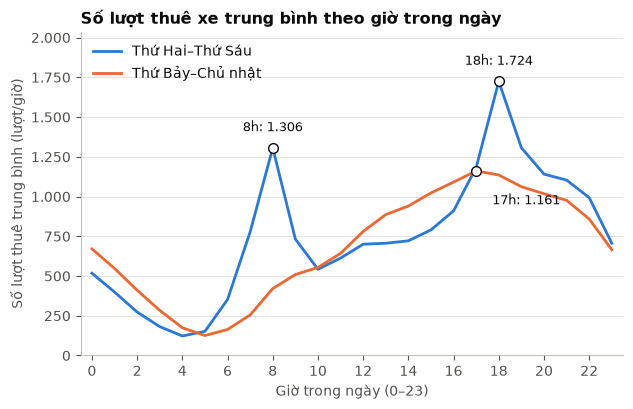

Đã lưu: figures\eda\03_luot_thue_theo_gio.png


In [16]:
# Hình 3 – Số lượt thuê trung bình theo giờ
fig, ax = plt.subplots()
for col, color in zip(by_hour_wk.columns, [BLUE, ORANGE]):
    ax.plot(by_hour_wk.index, by_hour_wk[col], color=color, lw=2, label=col)
wd = by_hour_wk['Thứ Hai–Thứ Sáu']
wk = by_hour_wk['Thứ Bảy–Chủ nhật']
for h, s, off in [(8, wd, (0, 12)), (18, wd, (0, 12)), (wk.loc[10:18].idxmax(), wk, (36, -24))]:
    ax.plot(h, s.loc[h], 'o', ms=7, color='white', mec=INK, zorder=5)
    ax.annotate(f'{h}h: {vn_num(s.loc[h])}', (h, s.loc[h]), xytext=off, textcoords='offset points',
                ha='center', fontsize=9)
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, wd.max() * 1.18)
ax.set_title('Số lượt thuê xe trung bình theo giờ trong ngày')
ax.set_xlabel('Giờ trong ngày (0–23)')
ax.set_ylabel('Số lượt thuê trung bình (lượt/giờ)')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(loc='upper left')
save_fig(fig, '03_luot_thue_theo_gio.png')

**Nhận xét.** Từ Thứ Hai đến Thứ Sáu, số lượt thuê có hai đỉnh nhọn lúc 8h (1.306 lượt/giờ) và 18h (1.724 lượt/giờ), trùng giờ đi làm và tan làm; thấp nhất lúc 4h (123 lượt/giờ). Cuối tuần không có đỉnh buổi sáng, số lượt thuê tăng dần đến khoảng 17h (1.161 lượt/giờ) rồi giảm.

## 6. So sánh theo mùa và theo ngày lễ

Dùng `groupby` và `pivot_table` để tổng hợp, sau đó vẽ boxplot (có đánh dấu trung bình) cho từng nhóm. Nhóm ngày lễ rất nhỏ so với ngày thường nên cần nêu cỡ mẫu và kiểm tra thêm ảnh hưởng của mùa.

In [17]:
agg = ['count', 'mean', 'median', 'std', 'min', 'max']
by_season = df_run.groupby('Seasons')[TARGET].agg(agg).reindex(SEASONS)
by_season.index = by_season.index.map(SEASON_VI)
by_holiday = df_run.groupby('Holiday')[TARGET].agg(agg).reindex(['No Holiday', 'Holiday'])
by_holiday.index = ['Ngày thường (No Holiday)', 'Ngày lễ (Holiday)']
# Pivot: trung bình theo giờ (dòng) x mùa (cột)
pivot_hour_season = df_run.pivot_table(index='Hour', columns='Seasons', values=TARGET, aggfunc='mean')[SEASONS]
pivot_hour_season.columns = [SEASON_VI[s] for s in SEASONS]
# Kiểm tra nhiễu: ngày lễ so với ngày thường trong từng mùa
holiday_by_season = df_run.pivot_table(index='Seasons', columns='Holiday', values=TARGET,
                                       aggfunc=['count', 'mean']).reindex(SEASONS)
holiday_by_season.index = holiday_by_season.index.map(SEASON_VI)
display(by_season.round(1))
display(by_holiday.round(1))
display(holiday_by_season.round(1))

,count,mean,median,std,min,max
Seasons,,,,,,
Xuân,2160,746.30,599.00,618.70,2,3251
Hạ,2208,"1,034.10",905.50,690.20,9,3556
Thu,1937,924.10,856.00,617.50,2,3298
Đông,2160,225.50,203.00,150.40,3,937


,count,mean,median,std,min,max
Ngày thường (No Holiday),8057,739.30,561.00,644.00,2,3556
Ngày lễ (Holiday),408,529.20,259.00,573.90,3,2400


count                mean           
Holiday Holiday No Holiday  Holiday No Holiday
Seasons                                       
Xuân         72       2088   635.30     750.10
Hạ           48       2160 1,022.10   1,034.30
Thu          96       1841   948.10     922.90
Đông        192       1968   156.60     232.30

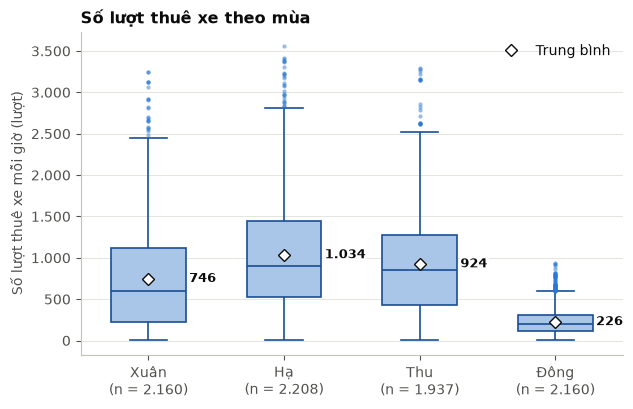

Đã lưu: figures\eda\04_luot_thue_theo_mua.png


In [18]:
def boxplot_groups(ax, data, x, order, labels, ylabel, legend=True):
    """Boxplot theo nhóm, đánh dấu trung bình (hình thoi trắng) và ghi cỡ mẫu dưới nhãn trục x."""
    sns.boxplot(data=data, x=x, y=TARGET, order=order, color=BLUE_LIGHT, linecolor=BLUE_DARK,
                linewidth=1.2, width=0.55, showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': INK, 'markersize': 6},
                flierprops={'marker': 'o', 'markerfacecolor': BLUE, 'markeredgecolor': 'none',
                            'markersize': 3, 'alpha': 0.5}, ax=ax)
    for i, g in enumerate(order):
        sub = data.loc[data[x] == g, TARGET]
        ax.text(i + 0.30, sub.mean(), vn_num(sub.mean()), va='center', ha='left', fontsize=9, fontweight='bold',
                bbox={'fc': 'white', 'ec': 'none', 'pad': 1, 'alpha': 0.85}, zorder=6)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f'{lb}\n(n = {vn_num((data[x] == g).sum())})' for g, lb in zip(order, labels)])
    ax.set_xlabel('')
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(THOUSANDS)
    if legend:
        ax.legend(handles=[Line2D([], [], marker='D', ls='', mfc='white', mec=INK, ms=6, label='Trung bình')],
                  loc='upper right')


# Hình 4 – So sánh theo mùa
fig, ax = plt.subplots()
boxplot_groups(ax, df_run, 'Seasons', SEASONS, [SEASON_VI[s] for s in SEASONS], 'Số lượt thuê xe mỗi giờ (lượt)')
ax.set_title('Số lượt thuê xe theo mùa')
save_fig(fig, '04_luot_thue_theo_mua.png')

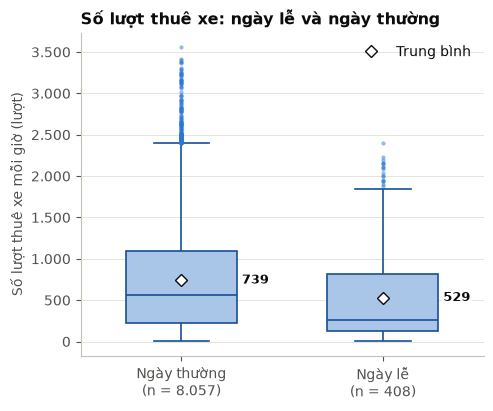

Đã lưu: figures\eda\05_ngay_le_va_ngay_thuong.png


In [19]:
# Hình 5 – Ngày lễ và ngày thường
fig, ax = plt.subplots(figsize=(5.2, 4.2))
boxplot_groups(ax, df_run, 'Holiday', ['No Holiday', 'Holiday'], ['Ngày thường', 'Ngày lễ'],
               'Số lượt thuê xe mỗi giờ (lượt)')
ax.set_title('Số lượt thuê xe: ngày lễ và ngày thường')
save_fig(fig, '05_ngay_le_va_ngay_thuong.png')

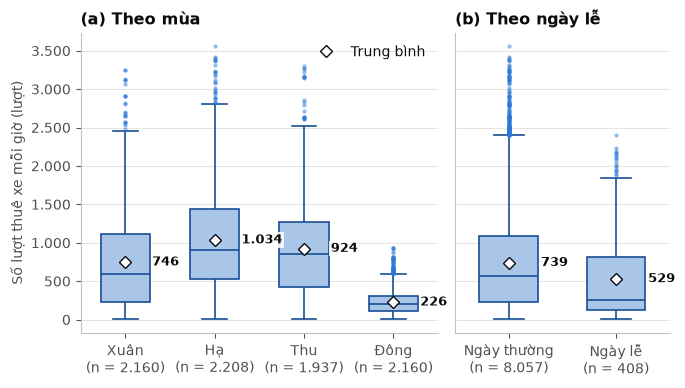

Đã lưu: figures\eda\04b_mua_va_ngay_le.png


In [20]:
# Hình ghép 4+5 (dùng trong báo cáo): (a) theo mùa, (b) theo ngày lễ, chung trục tung
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 3.9), sharey=True,
                             gridspec_kw={'width_ratios': [2, 1.2], 'wspace': 0.06})
boxplot_groups(a1, df_run, 'Seasons', SEASONS, [SEASON_VI[s] for s in SEASONS], 'Số lượt thuê xe mỗi giờ (lượt)')
boxplot_groups(a2, df_run, 'Holiday', ['No Holiday', 'Holiday'], ['Ngày thường', 'Ngày lễ'], '', legend=False)
a1.set_title('(a) Theo mùa')
a2.set_title('(b) Theo ngày lễ')
a2.tick_params(axis='y', left=False)
save_fig(fig, '04b_mua_va_ngay_le.png')

**Nhận xét.** Số lượt thuê trung bình cao nhất ở mùa Hạ (1.034), tiếp đến mùa Thu (924), mùa Xuân (746) và thấp nhất ở mùa Đông (226, chỉ khoảng 1/5 mùa Hạ); mùa Đông cũng ít biến động hơn (độ lệch chuẩn 150 so với 690 của mùa Hạ). Mùa Thu có 1.937 giờ vì 247 giờ ngừng hoạt động đã bị lọc.

Ngày lễ có trung bình 529 lượt/giờ, thấp hơn ngày thường (739) khoảng 28%. Tuy vậy 192 trong 408 giờ ngày lễ rơi vào mùa Đông là mùa có nhu cầu thấp. Khi so trong cùng một mùa, mức chênh nhỏ hơn rõ rệt hoặc đổi chiều (mùa Hạ: 1.022 so với 1.034; mùa Thu: 948 so với 923), nên phần chênh lệch chung chủ yếu do mùa chứ không chỉ do ngày lễ.

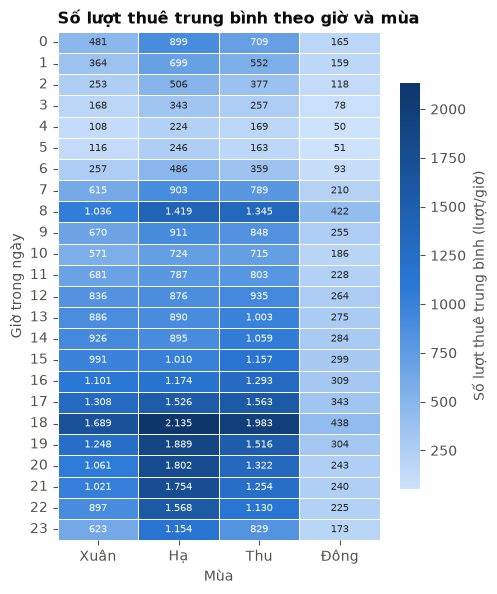

Đã lưu: figures\eda\09_phu_heatmap_gio_mua.png


In [21]:
# Hình phụ A1 – Heatmap của pivot (giờ x mùa): dùng cho slide/phụ lục
fig, ax = plt.subplots(figsize=(5.2, 6.6))
sns.heatmap(pivot_hour_season, cmap=CMAP_SEQ, annot=pivot_hour_season.map(lambda v: vn_num(v)), fmt='',
            annot_kws={'fontsize': 7.5}, linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Số lượt thuê trung bình (lượt/giờ)', 'shrink': 0.8}, ax=ax)
ax.grid(False)
ax.set_title('Số lượt thuê trung bình theo giờ và mùa')
ax.set_xlabel('Mùa')
ax.set_ylabel('Giờ trong ngày')
ax.tick_params(axis='y', rotation=0)
save_fig(fig, '09_phu_heatmap_gio_mua.png')

## 7. Nhiệt độ và lượng mưa

Scatter plot thể hiện quan hệ giữa nhiệt độ và số lượt thuê; đường màu cam nối trung bình của từng khoảng nhiệt độ 3 °C để thấy xu hướng. Với mưa, vì phần lớn các giờ không mưa nên nhóm theo mức mưa và nêu cỡ mẫu từng nhóm.

In [22]:
r_temp, p_temp = stats.pearsonr(df_run[TEMP], df_run[TARGET])
temp_bins = np.arange(np.floor(df_run[TEMP].min() / 3) * 3, df_run[TEMP].max() + 3, 3)
trend = (df_run.assign(bin=pd.cut(df_run[TEMP], temp_bins))
         .groupby('bin', observed=True).agg(temp_mid=(TEMP, 'mean'), mean=(TARGET, 'mean'), n=(TARGET, 'size')))
trend = trend[trend['n'] >= 20]          # bỏ khoảng có quá ít quan sát
print(f'Pearson r (nhiệt độ – số lượt thuê) = {r_temp:.3f}, {vn_p(p_temp)}')
display(trend.round(1).T)

Pearson r (nhiệt độ – số lượt thuê) = 0.563, p < 0,001


bin,"(-18.0, -15.0]","(-15.0, -12.0]","(-12.0, -9.0]","(-9.0, -6.0]","(-6.0, -3.0]","(-3.0, 0.0]","(0.0, 3.0]","(3.0, 6.0]","(6.0, 9.0]","(9.0, 12.0]","(12.0, 15.0]","(15.0, 18.0]","(18.0, 21.0]","(21.0, 24.0]","(24.0, 27.0]","(27.0, 30.0]","(30.0, 33.0]","(33.0, 36.0]","(36.0, 39.0]"
temp_mid,-15.80,-13.20,-10.50,-7.20,-4.50,-1.40,1.60,4.60,7.50,10.60,13.50,16.60,19.60,22.50,25.40,28.40,31.50,34.20,36.90
mean,104.70,154.60,149.10,188.50,197.00,242.80,287.20,418.30,529.20,656.10,810.80,869.60,971.70,"1,102.70","1,254.30","1,190.50","1,195.20","1,032.00",879.50
n,46.00,72.00,169.00,285.00,413.00,469.00,666.00,628.00,620.00,608.00,537.00,599.00,810.00,785.00,664.00,582.00,288.00,170.00,52.00


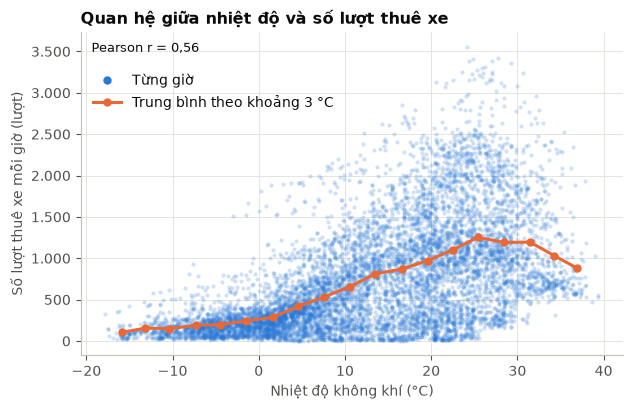

Đã lưu: figures\eda\06_nhiet_do_va_luot_thue.png


In [23]:
def draw_temp(ax, ylabel=True):
    """Scatter nhiệt độ – số lượt thuê kèm đường trung bình theo khoảng 3 °C."""
    ax.scatter(df_run[TEMP], df_run[TARGET], s=9, color=BLUE, alpha=0.22, linewidths=0)
    ax.plot(trend['temp_mid'], trend['mean'], color=ORANGE, lw=2.2, marker='o', ms=5)
    ax.set_xlabel('Nhiệt độ không khí (°C)')
    if ylabel:
        ax.set_ylabel('Số lượt thuê xe mỗi giờ (lượt)')
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.grid(axis='x', visible=True)
    ax.text(0.02, 0.97, f'Pearson r = {vn_num(r_temp, 2)}', transform=ax.transAxes, va='top', fontsize=9.5)
    ax.legend(handles=[Line2D([], [], marker='o', ls='', color=BLUE, ms=5, label='Từng giờ'),
                       Line2D([], [], marker='o', ls='-', lw=2.2, color=ORANGE, ms=5, label='Trung bình theo khoảng 3 °C')],
              loc='upper left', bbox_to_anchor=(0, 0.91))


# Hình 6 – Nhiệt độ và số lượt thuê
fig, ax = plt.subplots()
draw_temp(ax)
ax.set_title('Quan hệ giữa nhiệt độ và số lượt thuê xe')
save_fig(fig, '06_nhiet_do_va_luot_thue.png')

In [24]:
rain_labels = ['Không mưa', 'Mưa nhỏ\n(0–1 mm)', 'Mưa vừa\n(1–5 mm)', 'Mưa lớn\n(> 5 mm)']
df_run['RainLevel'] = pd.cut(df_run[RAIN], bins=[-np.inf, 0, 1, 5, np.inf], labels=rain_labels)
by_rain = df_run.groupby('RainLevel', observed=True)[TARGET].agg(['count', 'mean', 'median', 'std'])
by_rain.index = by_rain.index.astype(str).str.replace('\n', ' ')
# Kiểm tra nhiễu: giờ có mưa so với không mưa trong từng mùa
rain_by_season = df_run.assign(Mưa=np.where(df_run[RAIN] > 0, 'Có mưa', 'Không mưa')).pivot_table(
    index='Seasons', columns='Mưa', values=TARGET, aggfunc=['count', 'mean']).reindex(SEASONS)
rain_by_season.index = rain_by_season.index.map(SEASON_VI)
display(by_rain.round(1))
display(rain_by_season.round(1))

,count,mean,median,std
RainLevel,,,,
Không mưa,7949,765.60,591.00,642.70
Mưa nhỏ (0–1 mm),274,224.00,123.00,306.00
Mưa vừa (1–5 mm),178,113.70,38.00,200.50
Mưa lớn (> 5 mm),64,73.30,24.00,139.60


count             mean          
Mưa     Có mưa Không mưa Có mưa Không mưa
Seasons                                  
Xuân       191      1969  91.80    809.70
Hạ         197      2011 257.90  1,110.10
Thu         87      1850 165.30    959.80
Đông        41      2119  87.40    228.20

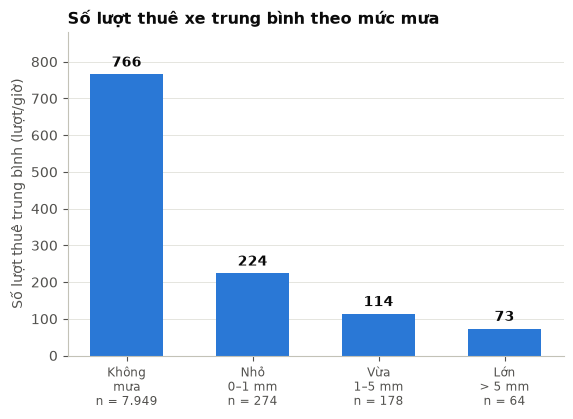

Đã lưu: figures\eda\07_anh_huong_luong_mua.png


In [25]:
cnt = df_run['RainLevel'].value_counts().reindex(rain_labels)
means = df_run.groupby('RainLevel', observed=True)[TARGET].mean().reindex(rain_labels)


def draw_rain(ax):
    """Cột trung bình số lượt thuê theo mức mưa; cỡ mẫu ghi dưới nhãn trục x."""
    ax.bar(range(4), means.values, width=0.58, color=BLUE)
    for i, m in enumerate(means.values):
        ax.text(i, m + 12, vn_num(m), ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_xticks(range(4))
    short = ['Không\nmưa', 'Nhỏ\n0–1 mm', 'Vừa\n1–5 mm', 'Lớn\n> 5 mm']
    ax.set_xticklabels([f'{lb}\nn = {vn_num(n)}' for lb, n in zip(short, cnt.values)], fontsize=8.5)
    ax.set_ylim(0, means.max() * 1.15)
    ax.set_ylabel('Số lượt thuê trung bình (lượt/giờ)')
    ax.yaxis.set_major_formatter(THOUSANDS)


# Hình 7 – Ảnh hưởng của lượng mưa
fig, ax = plt.subplots(figsize=(6.4, 4.2))
draw_rain(ax)
ax.set_title('Số lượt thuê xe trung bình theo mức mưa')
save_fig(fig, '07_anh_huong_luong_mua.png')

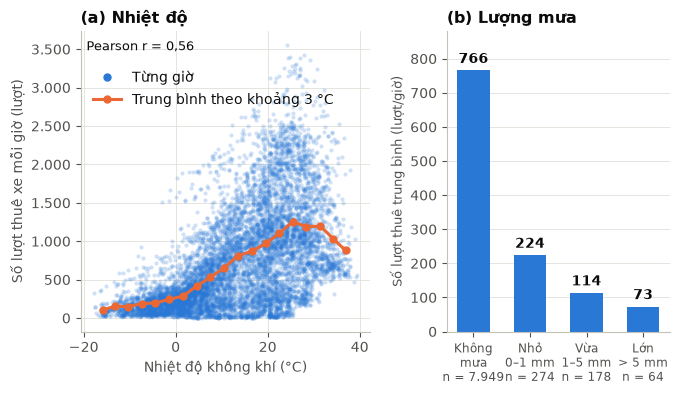

Đã lưu: figures\eda\06b_nhiet_do_va_mua.png


In [26]:
# Hình ghép 6+7 (dùng trong báo cáo): (a) nhiệt độ, (b) lượng mưa
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 3.9), gridspec_kw={'width_ratios': [1.3, 1], 'wspace': 0.3})
draw_temp(a1)
draw_rain(a2)
a1.set_title('(a) Nhiệt độ')
a2.set_title('(b) Lượng mưa')
a2.set_ylabel('Số lượt thuê trung bình (lượt/giờ)', fontsize=9)
save_fig(fig, '06b_nhiet_do_va_mua.png')

**Nhận xét.** Số lượt thuê tăng theo nhiệt độ (Pearson r = 0,56): trung bình từ khoảng 100 lượt/giờ ở −16 °C lên đỉnh khoảng 1.254 lượt/giờ ở 25 °C, sau đó giảm còn khoảng 1.032 ở 34 °C và 879 ở 37 °C. Quan hệ vì vậy không hoàn toàn tuyến tính: trời quá nóng làm nhu cầu giảm.

Chỉ 516 giờ (6,1%) có mưa nhưng nhu cầu giảm rất mạnh: 766 lượt/giờ khi không mưa, 224 khi mưa nhỏ (0–1 mm), 114 khi mưa vừa và 73 khi mưa lớn (trên 5 mm; chỉ có 64 giờ). Khi so trong từng mùa, giờ có mưa vẫn thấp hơn nhiều (ví dụ mùa Hạ: 258 so với 1.110), nên hiệu ứng của mưa không chỉ do mùa. Hệ số tương quan tuyến tính của lượng mưa với số lượt thuê chỉ −0,13 vì phần lớn các giờ có lượng mưa bằng 0.

## 8. Tương quan và heatmap

Ma trận tương quan Pearson cho các biến số (cộng với `Hour` và `IsWeekend`; không đưa `Month`, `DayOfWeek` vì thuộc nhóm phân loại). Với mỗi biến, tính thêm hệ số r và p-value so với số lượt thuê và xếp mức mạnh/yếu theo bảng của Bài 5: |r| ≥ 0,8 mạnh; 0,5–0,8 vừa; 0,3–0,5 yếu; dưới 0,3 gần như không có tương quan tuyến tính.

In [27]:
CORR_COLS = [TARGET, 'Hour', TEMP, HUM, WIND, VIS, DEW, SOLAR, RAIN, SNOW, 'IsWeekend']
corr = df_run[CORR_COLS].corr()


def strength(r):
    a = abs(r)
    return 'Mạnh' if a >= 0.8 else 'Vừa' if a >= 0.5 else 'Yếu' if a >= 0.3 else 'Gần như không'


rows = []
for c in CORR_COLS[1:]:
    r = corr.loc[c, TARGET]                                  # cùng nguồn với heatmap để số liệu khớp nhau
    p = stats.pearsonr(df_run[c], df_run[TARGET])[1]
    rows.append({'Biến': LABEL_VI[c], 'Cột': c, 'Pearson r': r, 'p-value': p,
                 'Mức tương quan': strength(r), 'Chiều': 'Thuận' if r > 0 else 'Nghịch'})
corr_target = pd.DataFrame(rows).sort_values('Pearson r', key=abs, ascending=False).reset_index(drop=True)

# Cặp biến đầu vào có tương quan cao (|r| >= 0,8): cảnh báo đa cộng tuyến cho bước dựng mô hình
feat = CORR_COLS[1:]
collinear = [(LABEL_VI[a], LABEL_VI[b], corr.loc[a, b]) for a, b in combinations(feat, 2) if abs(corr.loc[a, b]) >= 0.8]
print('Cặp biến đầu vào có |r| >= 0,8:', [(a, b, round(r, 2)) for a, b, r in collinear])
display(corr_target.assign(**{'p-value': corr_target['p-value'].map(vn_p)}).round(3))

Cặp biến đầu vào có |r| >= 0,8: [('Nhiệt độ', 'Điểm sương', np.float64(0.91))]


,Biến,Cột,Pearson r,p-value,Mức tương quan,Chiều
0,Nhiệt độ,Temperature(°C),0.56,"p < 0,001",Vừa,Thuận
1,Giờ,Hour,0.42,"p < 0,001",Yếu,Thuận
2,Điểm sương,Dew point temperature(°C),0.40,"p < 0,001",Yếu,Thuận
3,Bức xạ mặt trời,Solar Radiation (MJ/m2),0.27,"p < 0,001",Gần như không,Thuận
4,Tầm nhìn,Visibility (10m),0.21,"p < 0,001",Gần như không,Thuận
5,Độ ẩm,Humidity(%),-0.20,"p < 0,001",Gần như không,Nghịch
6,Lượng tuyết,Snowfall (cm),-0.15,"p < 0,001",Gần như không,Nghịch
7,Lượng mưa,Rainfall(mm),-0.13,"p < 0,001",Gần như không,Nghịch
8,Tốc độ gió,Wind speed (m/s),0.12,"p < 0,001",Gần như không,Thuận
9,Cuối tuần,IsWeekend,-0.05,"p < 0,001",Gần như không,Nghịch


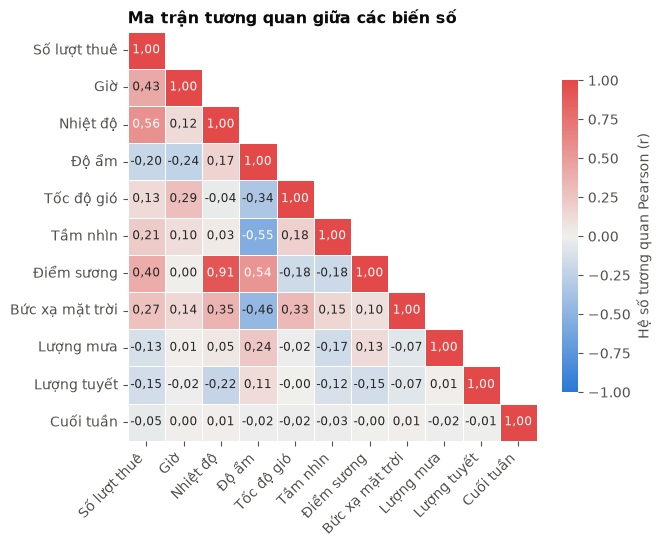

Đã lưu: figures\eda\08_heatmap_tuong_quan.png


In [28]:
# Hình 8 – Heatmap tương quan (chỉ hiển thị nửa dưới ma trận)
labels = [LABEL_VI[c] for c in CORR_COLS]
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(6.6, 5.4))
sns.heatmap(corr.set_axis(labels, axis=0).set_axis(labels, axis=1), mask=mask, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0,
            annot=corr.map(lambda v: vn_num(v, 2)).set_axis(labels, axis=0).set_axis(labels, axis=1), fmt='',
            annot_kws={'fontsize': 8.5}, linewidths=0.6, linecolor='white', square=True,
            cbar_kws={'label': 'Hệ số tương quan Pearson (r)', 'shrink': 0.75}, ax=ax)
ax.grid(False)
ax.set_title('Ma trận tương quan giữa các biến số')
ax.tick_params(axis='x', rotation=45)
plt.setp(ax.get_xticklabels(), ha='right')
save_fig(fig, '08_heatmap_tuong_quan.png')

**Nhận xét.** Nhiệt độ có tương quan dương mạnh nhất với số lượt thuê (r = 0,56, mức vừa); giờ trong ngày (0,43) và điểm sương (0,40) ở mức yếu; các biến còn lại dưới 0,3. Điểm cần lưu ý cho bước xây dựng mô hình: nhiệt độ và điểm sương tương quan rất cao với nhau (r = 0,91), tức là hai biến mang thông tin gần như trùng nhau (đa cộng tuyến); độ ẩm cũng tương quan đáng kể với tầm nhìn (−0,55) và điểm sương (0,54).

## 9. Phân tích phương sai (ANOVA một yếu tố)

**Câu hỏi:** số lượt thuê trung bình giữa bốn mùa có khác nhau có ý nghĩa thống kê không?

- **H0:** trung bình số lượt thuê của bốn mùa (Xuân, Hạ, Thu, Đông) bằng nhau.
- **H1:** có ít nhất một mùa có trung bình khác các mùa còn lại.
- **Mức ý nghĩa:** α = 0,05. Dùng `scipy.stats.f_oneway` (Bài 5); kết quả được kiểm tra lại bằng cách tính F thủ công từ tổng bình phương giữa nhóm và trong nhóm.
- Nếu p-value < α thì bác bỏ H0. Khi bác bỏ H0, so sánh từng cặp mùa (6 cặp) bằng `f_oneway` cho hai nhóm; để giữ mức sai lầm chung 0,05 khi làm 6 phép thử, mỗi cặp so với ngưỡng 0,05 / 6 ≈ 0,0083 (hiệu chỉnh Bonferroni).

In [29]:
def anova_oneway(d, group_col, order=None, value_col=TARGET):
    """ANOVA một yếu tố bằng f_oneway; trả về dict kết quả kèm kiểm tra F thủ công và eta bình phương."""
    order = order if order is not None else sorted(d[group_col].unique())
    groups = [d.loc[d[group_col] == g, value_col].to_numpy() for g in order]
    f, p = stats.f_oneway(*groups)
    allv = np.concatenate(groups)
    ss_between = sum(len(g) * (g.mean() - allv.mean()) ** 2 for g in groups)
    ss_within = sum(((g - g.mean()) ** 2).sum() for g in groups)
    df_b, df_w = len(groups) - 1, len(allv) - len(groups)
    f_manual = (ss_between / df_b) / (ss_within / df_w)
    assert np.isclose(f, f_manual), (f, f_manual)           # kiểm tra chéo công thức F
    return {'k': len(groups), 'N': len(allv), 'df_between': df_b, 'df_within': df_w, 'F': f, 'p': p,
            'eta2': ss_between / (ss_between + ss_within)}


anova_run = anova_oneway(df_run, 'Seasons', SEASONS)
anova_all = anova_oneway(df_all, 'Seasons', SEASONS)          # đối chiếu với toàn bộ 8.760 giờ
decision = 'Bác bỏ H0' if anova_run['p'] < ALPHA else 'Không bác bỏ H0'
print(f"Giờ hoạt động: F({anova_run['df_between']}; {anova_run['df_within']}) = {anova_run['F']:.1f}, {vn_p(anova_run['p'])}, eta² = {anova_run['eta2']:.3f} → {decision}")
print(f"Toàn bộ 8.760 giờ (đối chiếu): F = {anova_all['F']:.1f}, {vn_p(anova_all['p'])}")
group_stats = df_run.groupby('Seasons')[TARGET].agg(['count', 'mean', 'std']).reindex(SEASONS)
group_stats.index = group_stats.index.map(SEASON_VI)
display(group_stats.round(1))

Giờ hoạt động: F(3; 8461) = 875.6, p < 0,001, eta² = 0.237 → Bác bỏ H0
Toàn bộ 8.760 giờ (đối chiếu): F = 776.5, p < 0,001


,count,mean,std
Seasons,,,
Xuân,2160,746.30,618.70
Hạ,2208,"1,034.10",690.20
Thu,1937,924.10,617.50
Đông,2160,225.50,150.40


In [30]:
# So sánh từng cặp mùa (Bonferroni)
alpha_pair = ALPHA / len(list(combinations(SEASONS, 2)))
pair_rows = []
for a, b in combinations(SEASONS, 2):
    sub = df_run[df_run['Seasons'].isin([a, b])]
    res = anova_oneway(sub, 'Seasons', [a, b])
    pair_rows.append({'Cặp mùa': f'{SEASON_VI[a]} – {SEASON_VI[b]}',
                      'TB mùa thứ nhất': df_run.loc[df_run['Seasons'] == a, TARGET].mean(),
                      'TB mùa thứ hai': df_run.loc[df_run['Seasons'] == b, TARGET].mean(),
                      'F': res['F'], 'p-value': res['p'],
                      'Kết luận': 'Khác biệt có ý nghĩa' if res['p'] < alpha_pair else 'Chưa đủ bằng chứng'})
pairwise = pd.DataFrame(pair_rows)
print(f'Ngưỡng Bonferroni cho mỗi cặp: {alpha_pair:.4f}')
display(pairwise.assign(**{'p-value': pairwise['p-value'].map(vn_p)}).round(1))

Ngưỡng Bonferroni cho mỗi cặp: 0.0083


,Cặp mùa,TB mùa thứ nhất,TB mùa thứ hai,F,p-value,Kết luận
0,Xuân – Hạ,746.30,"1,034.10",210.30,"p < 0,001",Khác biệt có ý nghĩa
1,Xuân – Thu,746.30,924.10,84.50,"p < 0,001",Khác biệt có ý nghĩa
2,Xuân – Đông,746.30,225.50,"1,444.80","p < 0,001",Khác biệt có ý nghĩa
3,Hạ – Thu,"1,034.10",924.10,28.90,"p < 0,001",Khác biệt có ý nghĩa
4,Hạ – Đông,"1,034.10",225.50,"2,832.20","p < 0,001",Khác biệt có ý nghĩa
5,Thu – Đông,924.10,225.50,"2,592.60","p < 0,001",Khác biệt có ý nghĩa


**Kết luận ANOVA.** F(3; 8.461) = 875,6 với p-value < 0,001, nhỏ hơn α = 0,05 nên bác bỏ H0: số lượt thuê trung bình giữa bốn mùa khác nhau có ý nghĩa thống kê. Mùa giải thích khoảng 23,7% biến thiên của số lượt thuê (eta² = 0,237). Cả 6 cặp mùa đều khác biệt có ý nghĩa ở ngưỡng Bonferroni 0,0083, trong đó khác biệt lớn nhất là mùa Hạ – mùa Đông (F = 2.832,2) và nhỏ nhất là mùa Hạ – mùa Thu (F = 28,9).

**Lưu ý khi diễn giải.** Phương sai các mùa không đều (độ lệch chuẩn từ 150 đến 690) và số lượt thuê lệch phải, trong khi ANOVA chuẩn giả định phương sai gần bằng nhau. Vì F rất lớn nên kết luận không thay đổi, nhưng nên hiểu kết quả là bằng chứng mạnh về khác biệt giữa các mùa chứ không phải thước đo chính xác của độ lớn khác biệt.

## 10. Chọn biến quan trọng (đầu vào cho bước xây dựng mô hình)

Theo hướng dẫn ở cuối Bài 5: biến số được chọn khi |r| ≥ 0,3 với số lượt thuê; biến phân loại được chọn khi ANOVA có p-value < 0,05. `Hour` (24 nhóm) và `DayOfWeek` (7 nhóm) cũng được kiểm tra như biến phân loại vì quan hệ của giờ với số lượt thuê không tuyến tính (có hai đỉnh).

In [31]:
cat_tests = []
for col, label, order in [('Seasons', 'Mùa (Seasons)', SEASONS), ('Holiday', 'Ngày lễ (Holiday)', None),
                          ('Hour', 'Giờ (Hour, xét như biến phân loại)', None),
                          ('DayOfWeek', 'Thứ trong tuần (DayOfWeek)', None), ('Month', 'Tháng (Month)', None)]:
    res = anova_oneway(df_run, col, order)
    cat_tests.append({'Biến': label, 'Số nhóm': res['k'], 'F': res['F'], 'p-value': res['p'], 'eta²': res['eta2'],
                      'Chọn?': 'Có' if res['p'] < ALPHA else 'Không'})
cat_tests = pd.DataFrame(cat_tests)

num_sel = corr_target[['Biến', 'Pearson r', 'p-value', 'Mức tương quan']].copy()
num_sel['Chọn? (|r| ≥ 0,3)'] = np.where(num_sel['Pearson r'].abs() >= 0.3, 'Có', 'Không')
display(num_sel.assign(**{'p-value': num_sel['p-value'].map(vn_p)}).round(3))
display(cat_tests.assign(**{'p-value': cat_tests['p-value'].map(vn_p)}).round(3))

,Biến,Pearson r,p-value,Mức tương quan,"Chọn? (|r| ≥ 0,3)"
0,Nhiệt độ,0.56,"p < 0,001",Vừa,Có
1,Giờ,0.42,"p < 0,001",Yếu,Có
2,Điểm sương,0.40,"p < 0,001",Yếu,Có
3,Bức xạ mặt trời,0.27,"p < 0,001",Gần như không,Không
4,Tầm nhìn,0.21,"p < 0,001",Gần như không,Không
5,Độ ẩm,-0.20,"p < 0,001",Gần như không,Không
6,Lượng tuyết,-0.15,"p < 0,001",Gần như không,Không
7,Lượng mưa,-0.13,"p < 0,001",Gần như không,Không
8,Tốc độ gió,0.12,"p < 0,001",Gần như không,Không
9,Cuối tuần,-0.05,"p < 0,001",Gần như không,Không


,Biến,Số nhóm,F,p-value,eta²,Chọn?
0,Mùa (Seasons),4,875.60,"p < 0,001",0.24,Có
1,Ngày lễ (Holiday),2,41.76,"p < 0,001",0.01,Có
2,"Giờ (Hour, xét như biến phân loại)",24,168.17,"p < 0,001",0.31,Có
3,Thứ trong tuần (DayOfWeek),7,6.28,"p < 0,001",0.00,Có
4,Tháng (Month),12,310.95,"p < 0,001",0.29,Có


**Nhận xét.** Theo quy tắc của Bài 5, ba biến số được chọn là nhiệt độ, giờ và điểm sương; cả năm biến phân loại đều có p-value < 0,05 nên đều được chọn. Với cỡ mẫu hơn 8.000 dòng, p-value rất nhỏ ngay cả khi ảnh hưởng thực tế không đáng kể, vì vậy cần đọc cùng eta²: giờ (0,31), tháng (0,29) và mùa (0,24) giải thích nhiều biến thiên, còn thứ trong tuần (0,004) và ngày lễ (0,005) gần như không đáng kể. Nhiệt độ và điểm sương gần như trùng thông tin (r = 0,91) nên không nên đưa cả hai vào cùng một mô hình tuyến tính nếu không xử lý đa cộng tuyến (ví dụ dùng Ridge).

## 11. Xuất bảng thống kê và kết quả ANOVA ra Excel

Hai file này dùng làm nguồn số liệu cho báo cáo; số trong báo cáo, bảng và hình đều lấy từ đây.

In [32]:
def write_excel(path, sheets):
    """Ghi nhiều bảng vào một file Excel; sheets = {tên: (DataFrame, ghi_index)}. Tự chỉnh độ rộng cột."""
    with pd.ExcelWriter(path, engine='openpyxl') as xw:
        for name, (d, with_index) in sheets.items():
            d.to_excel(xw, sheet_name=name[:31], index=with_index)
            ws = xw.sheets[name[:31]]
            ws.freeze_panes = 'B2'
            for col in ws.columns:
                width = max(len(str(c.value)) if c.value is not None else 0 for c in col)
                ws.column_dimensions[col[0].column_letter].width = min(max(10, width + 2), 48)
    print('Đã lưu:', path)


def flat_cols(d):
    """Làm phẳng tiêu đề cột nhiều tầng (vd. count_Holiday) để ghi ra Excel gọn gàng."""
    d = d.copy()
    d.columns = ['_'.join(map(str, c)) for c in d.columns]
    return d


overview = pd.DataFrame({
    'Chỉ số': ['Số dòng (toàn bộ)', 'Số giờ ngừng hoạt động (bị lọc)', 'Số dòng dùng để phân tích', 'Ngưỡng ngoại lệ trên (Q3 + 1,5 IQR)',
               'Số giờ ngoại lệ', 'Giờ có trung bình cao nhất', 'Giờ có trung bình thấp nhất', 'Giờ đỉnh buổi sáng (6–10h)',
               'Số giờ có mưa', 'Số ngày lễ', 'Số giờ ngày lễ (giờ hoạt động)'],
    'Giá trị': [len(df_all), int((df_all['Functioning Day'] == 'No').sum()), len(df_run), upper_fence, n_out, int(peak_h),
                int(low_h), int(morning_h), int((df_run[RAIN] > 0).sum()),
                int(df_all.loc[df_all['Holiday'] == 'Holiday', 'Date'].nunique()), int((df_run['Holiday'] == 'Holiday').sum())]})

write_excel('descriptive_statistics.xlsx', {
    'TongQuan': (overview, False),
    'MoTa_MucTieu_2PhienBan': (desc_target.round(3), True),
    'MoTa_BienSo_HoatDong': (desc_run.round(3), True),
    'MoTa_BienSo_ToanBo': (desc_all.round(3), True),
    'PhanLoai_CoMau': (cat_counts, True),
    'GroupBy_Gio': (by_hour.join(by_hour_wk.round(2)), True),
    'GroupBy_Mua': (by_season.round(2), True),
    'GroupBy_NgayLe': (by_holiday.round(2), True),
    'GroupBy_MucMua': (by_rain.round(2), True),
    'NgayLe_Theo_Mua': (flat_cols(holiday_by_season).round(2), True),
    'CoMua_Theo_Mua': (flat_cols(rain_by_season).round(2), True),
    'Pivot_Gio_x_Mua': (pivot_hour_season.round(2), True),
    'NgoaiLe_TheoGio': (out_hour, True),
    'NgoaiLe_TheoMua': (out_season, True),
    'XuHuong_NhietDo': (trend.reset_index(drop=True).round(2), False),
    'TuongQuan_MaTran': (corr.set_axis(labels, axis=0).set_axis(labels, axis=1).round(3), True),
    'TuongQuan_VoiMucTieu': (corr_target, False),
    'ChonBien_BienSo': (num_sel, False),
    'ChonBien_PhanLoai': (cat_tests, False),
})

Đã lưu: descriptive_statistics.xlsx


In [33]:
anova_table = pd.DataFrame({
    'Mục': ['Biến mục tiêu', 'Yếu tố (nhóm)', 'Dữ liệu', 'H0', 'H1', 'Mức ý nghĩa α', 'Số nhóm (k)', 'Tổng số quan sát (N)',
            'Bậc tự do giữa nhóm', 'Bậc tự do trong nhóm', 'Thống kê F', 'p-value (scipy; 0 = nhỏ hơn giới hạn biểu diễn của máy)', 'p-value (hiển thị)', 'eta² (độ lớn hiệu ứng)',
            'Quyết định', 'Kết luận'],
    'Giá trị': ['Rented Bike Count (lượt thuê/giờ)', 'Seasons (Xuân, Hạ, Thu, Đông)', 'Giờ hoạt động (Functioning Day = Yes)',
                'Trung bình số lượt thuê của 4 mùa bằng nhau', 'Có ít nhất một mùa có trung bình khác các mùa còn lại', ALPHA,
                anova_run['k'], anova_run['N'], anova_run['df_between'], anova_run['df_within'], round(anova_run['F'], 2),
                anova_run['p'], vn_p(anova_run['p']), round(anova_run['eta2'], 4), decision,
                'Số lượt thuê trung bình giữa các mùa khác nhau có ý nghĩa thống kê ở mức 0,05' if anova_run['p'] < ALPHA
                else 'Chưa đủ bằng chứng cho thấy trung bình các mùa khác nhau ở mức 0,05']})

anova_ref = pd.DataFrame({'Phiên bản dữ liệu': ['Giờ hoạt động (8.465 giờ)', 'Toàn bộ (8.760 giờ, đối chiếu)'],
                          'N': [anova_run['N'], anova_all['N']], 'F': [anova_run['F'], anova_all['F']],
                          'p-value': [vn_p(anova_run['p']), vn_p(anova_all['p'])],
                          'eta²': [anova_run['eta2'], anova_all['eta2']]}).round(3)

write_excel('anova_result.xlsx', {
    'ANOVA_Mua': (anova_table, False),
    'Thong_ke_nhom': (group_stats.round(2), True),
    'So_sanh_tung_cap': (pairwise.assign(**{'p-value (hiển thị)': pairwise['p-value'].map(vn_p)}).round(3), False),
    'Doi_chieu_2_phien_ban': (anova_ref, False),
    'ANOVA_bien_phan_loai': (cat_tests.assign(**{'p-value (hiển thị)': cat_tests['p-value'].map(vn_p)}).round(3), False),
})

Đã lưu: anova_result.xlsx


## 12. Hình quy trình phân tích (dùng trong mục Phương pháp phân tích của báo cáo)

Hình vẽ bằng code, thể hiện đúng các bước nhóm đã thực hiện: chuẩn bị dữ liệu, phân tích thăm dò và xây dựng mô hình hồi quy.

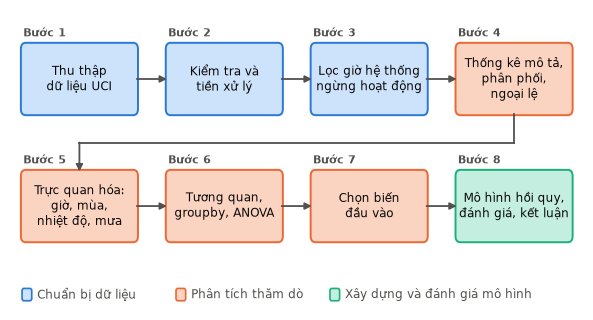

Đã lưu: figures\eda\00_quy_trinh.png


In [34]:
steps = [
    (0, 0, 'Thu thập\ndữ liệu UCI', 0), (1, 0, 'Kiểm tra và\ntiền xử lý', 0), (2, 0, 'Lọc giờ hệ thống\nngừng hoạt động', 0),
    (3, 0, 'Thống kê mô tả,\nphân phối,\nngoại lệ', 1),
    (0, 1, 'Trực quan hóa:\ngiờ, mùa,\nnhiệt độ, mưa', 1), (1, 1, 'Tương quan,\ngroupby, ANOVA', 1),
    (2, 1, 'Chọn biến\nđầu vào', 1), (3, 1, 'Mô hình hồi quy,\nđánh giá, kết luận', 2),
]
stage_fill = ['#cde2fb', '#fbd3c1', '#c4efe0']
stage_edge = [BLUE, ORANGE, '#1baf7a']
stage_name = ['Chuẩn bị dữ liệu', 'Phân tích thăm dò', 'Xây dựng và đánh giá mô hình']
W, H, GX, GY = 1.9, 0.9, 0.5, 0.75

fig, ax = plt.subplots(figsize=(7.4, 3.9))
ax.set_axis_off()
ax.set_xlim(-0.2, 4 * W + 3 * GX + 0.2)
ax.set_ylim(-0.9, 2 * H + GY + 0.45)
pos = {}
for i, (cx, cy, text, stage) in enumerate(steps):
    x, y0 = cx * (W + GX), (1 - cy) * (H + GY)
    ax.add_patch(FancyBboxPatch((x, y0), W, H, boxstyle='round,pad=0.02,rounding_size=0.08',
                                fc=stage_fill[stage], ec=stage_edge[stage], lw=1.4))
    ax.text(x + W / 2, y0 + H / 2, text, ha='center', va='center', fontsize=8.6)
    ax.text(x + 0.02, y0 + H + 0.07, f'Bước {i + 1}', ha='left', va='bottom', fontsize=8, color=INK2, fontweight='bold')
    pos[i] = (x, y0)
arrow = {'arrowstyle': '-|>', 'color': INK2, 'lw': 1.3, 'shrinkA': 0, 'shrinkB': 0}
for i in range(7):
    (xa, ya), (xb, yb) = pos[i], pos[i + 1]
    if i == 3:       # chuyển dòng: từ ô 4 (phải, trên) xuống ô 5 (trái, dưới) bằng đường gấp khúc
        ym = ya - GY / 2
        ax.plot([xa + W / 2, xa + W / 2], [ya, ym], color=INK2, lw=1.3)
        ax.plot([xa + W / 2, xb + W / 2], [ym, ym], color=INK2, lw=1.3)
        ax.annotate('', xy=(xb + W / 2, yb + H), xytext=(xb + W / 2, ym), arrowprops=arrow)
    else:
        ax.annotate('', xy=(xb, yb + H / 2), xytext=(xa + W, ya + H / 2), arrowprops=arrow)
for k in range(3):
    ax.add_patch(FancyBboxPatch((k * 2.55, -0.78), 0.16, 0.16, boxstyle='round,pad=0,rounding_size=0.03',
                                fc=stage_fill[k], ec=stage_edge[k], lw=1.2, clip_on=False))
    ax.text(k * 2.55 + 0.25, -0.70, stage_name[k], va='center', fontsize=8.5, color=INK2)
save_fig(fig, '00_quy_trinh.png')

## 13. Dashboard tổng hợp

Gộp các phát hiện chính của Phần B vào **một hình** để dùng cho báo cáo và slide: bốn chỉ số
tóm tắt ở trên, rồi nhu cầu theo giờ, theo mùa, theo nhiệt độ và theo mức mưa. Hình được vẽ
bằng code từ chính các bảng đã tính ở các mục trên (`by_hour_wk`, `by_season`, `trend`,
`means`) nên số liệu khớp với Bảng 2-3 và Hình 2-6, không nhập tay. Tên tệp:
`figures/eda/10_dashboard_tong_hop.png`.

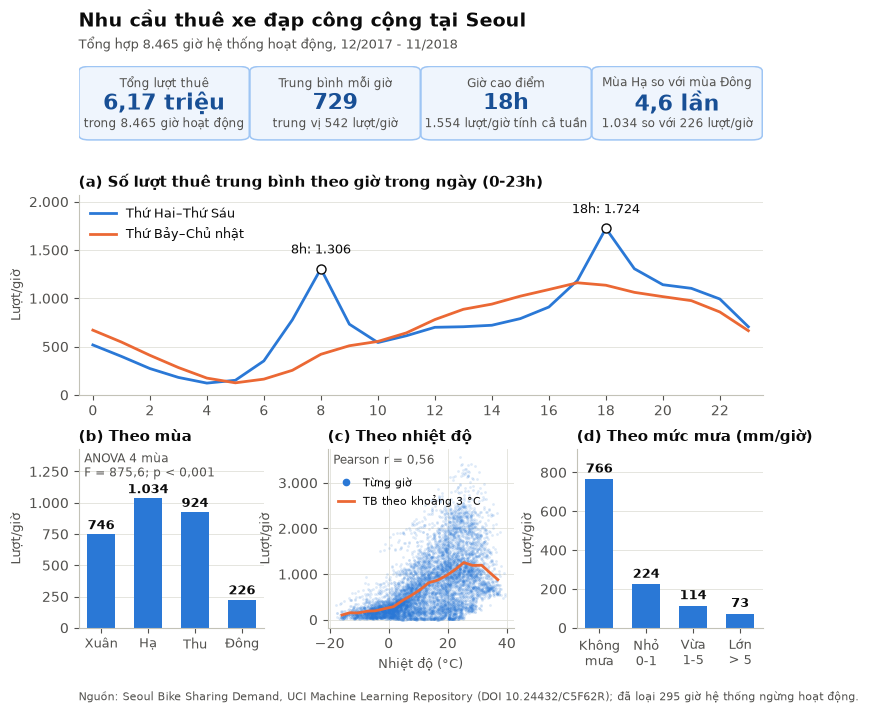

Đã lưu: figures\eda\10_dashboard_tong_hop.png
Mưa lớn (> 5 mm) thấp hơn giờ không mưa 90%


In [35]:
# Hình dashboard_tong_hop - một hình tóm tắt Phần B (dùng cho báo cáo và slide)
# Số liệu lấy lại từ các bảng đã tính ở trên, không tính lại để tránh lệch số.
peak_h = by_hour['mean'].idxmax()
season_hi, season_lo = by_season['mean'].idxmax(), by_season['mean'].idxmin()
season_ratio = by_season['mean'].max() / by_season['mean'].min()
rain_drop = 1 - means.iloc[-1] / means.iloc[0]

kpis = [
    ('Tổng lượt thuê', vn_num(df_run[TARGET].sum() / 1e6, 2) + ' triệu', f'trong {vn_num(len(df_run))} giờ hoạt động'),
    ('Trung bình mỗi giờ', vn_num(df_run[TARGET].mean()), f'trung vị {vn_num(df_run[TARGET].median())} lượt/giờ'),
    ('Giờ cao điểm', f'{peak_h}h', f'{vn_num(by_hour.loc[peak_h, "mean"])} lượt/giờ tính cả tuần'),
    (f'Mùa {season_hi} so với mùa {season_lo}', vn_num(season_ratio, 1) + ' lần',
     f'{vn_num(by_season["mean"].max())} so với {vn_num(by_season["mean"].min())} lượt/giờ'),
]

fig = plt.figure(figsize=(7.6, 7.3))
gs = fig.add_gridspec(3, 3, height_ratios=[0.42, 1.12, 1.0], hspace=0.36, wspace=0.34,
                      left=0.085, right=0.985, top=0.885, bottom=0.115)
fig.text(0.085, 0.962, 'Nhu cầu thuê xe đạp công cộng tại Seoul', ha='left', va='top',
         fontsize=13.5, fontweight='bold', color=INK)
fig.text(0.085, 0.925, f'Tổng hợp {vn_num(len(df_run))} giờ hệ thống hoạt động, 12/2017 - 11/2018',
         ha='left', va='top', fontsize=9.5, color=INK2)

# ---- Hàng chỉ số: 4 thẻ số, không vẽ biểu đồ vì mỗi ô chỉ có một con số ----------------
ax_kpi = fig.add_subplot(gs[0, :])
ax_kpi.set_axis_off()
ax_kpi.set_xlim(0, 4)
ax_kpi.set_ylim(0, 1)
for i, (label, value, note) in enumerate(kpis):
    ax_kpi.add_patch(FancyBboxPatch((i + 0.012, 0.02), 0.976, 0.96,
                                    boxstyle='round,pad=0.01,rounding_size=0.06',
                                    fc='#eff5fd', ec=BLUE_LIGHT, lw=1.1))
    ax_kpi.text(i + 0.5, 0.86, label, ha='center', va='top', fontsize=8.8, color=INK2)
    ax_kpi.text(i + 0.5, 0.50, value, ha='center', va='center', fontsize=16, fontweight='bold', color=BLUE_DARK)
    ax_kpi.text(i + 0.5, 0.14, note, ha='center', va='bottom', fontsize=8.4, color=INK2)

# ---- (a) Theo giờ: hai chuỗi nên có chú giải, đánh dấu riêng hai đỉnh ngày thường ------
ax_a = fig.add_subplot(gs[1, :])
for col, color in zip(by_hour_wk.columns, [BLUE, ORANGE]):
    ax_a.plot(by_hour_wk.index, by_hour_wk[col], color=color, lw=2, label=col)
wd = by_hour_wk['Thứ Hai–Thứ Sáu']
for h, off in [(morning_h, (0, 11)), (peak_h, (0, 11))]:
    ax_a.plot(h, wd.loc[h], 'o', ms=6.5, color='white', mec=INK, zorder=5)
    ax_a.annotate(f'{h}h: {vn_num(wd.loc[h])}', (h, wd.loc[h]), xytext=off, textcoords='offset points',
                  ha='center', fontsize=9.2)
ax_a.set_xticks(range(0, 24, 2))
ax_a.set_xlim(-0.5, 23.5)
ax_a.set_ylim(0, wd.max() * 1.2)
ax_a.set_title('(a) Số lượt thuê trung bình theo giờ trong ngày (0-23h)', fontsize=10.8)
ax_a.set_ylabel('Lượt/giờ', fontsize=9.6)
ax_a.yaxis.set_major_formatter(THOUSANDS)
ax_a.legend(loc='upper left', fontsize=9.2)

# ---- (b) Theo mùa: một màu cho cả bốn cột vì chiều cao đã mang thông tin ---------------
ax_b = fig.add_subplot(gs[2, 0])
ax_b.bar(range(4), by_season['mean'].values, width=0.6, color=BLUE)
for i, v in enumerate(by_season['mean'].values):
    ax_b.text(i, v + 18, vn_num(v), ha='center', va='bottom', fontsize=9.2, fontweight='bold')
ax_b.set_xticks(range(4))
ax_b.set_xticklabels(by_season.index, fontsize=9.2)
ax_b.set_ylim(0, by_season['mean'].max() * 1.38)
ax_b.set_title('(b) Theo mùa', fontsize=10.8)
ax_b.set_ylabel('Lượt/giờ', fontsize=9.6)
ax_b.yaxis.set_major_formatter(THOUSANDS)
ax_b.text(0.03, 0.99, f"ANOVA 4 mùa\nF = {vn_num(anova_run['F'], 1)}; {vn_p(anova_run['p'])}",
          transform=ax_b.transAxes, va='top', fontsize=8.4, color=INK2)

# ---- (c) Nhiệt độ: từng giờ mờ phía sau, đường trung bình theo khoảng 3 °C phía trước --
ax_c = fig.add_subplot(gs[2, 1])
ax_c.scatter(df_run[TEMP], df_run[TARGET], s=4, color=BLUE, alpha=0.15, linewidths=0)
ax_c.plot(trend['temp_mid'], trend['mean'], color=ORANGE, lw=2)
ax_c.set_title('(c) Theo nhiệt độ', fontsize=10.8)
ax_c.set_xlabel('Nhiệt độ (°C)', fontsize=9.6)
ax_c.set_ylabel('Lượt/giờ', fontsize=9.6)
ax_c.yaxis.set_major_formatter(THOUSANDS)
ax_c.grid(axis='x', visible=True)
ax_c.text(0.03, 0.97, f'Pearson r = {vn_num(r_temp, 2)}', transform=ax_c.transAxes, va='top', fontsize=8.6, color=INK2)
ax_c.legend(handles=[Line2D([], [], marker='o', ls='', color=BLUE, ms=4.5, label='Từng giờ'),
                     Line2D([], [], ls='-', lw=2, color=ORANGE, label='TB theo khoảng 3 °C')],
            loc='upper left', bbox_to_anchor=(0, 0.9), fontsize=8.2, handlelength=1.4)

# ---- (d) Theo mức mưa -----------------------------------------------------------------
ax_d = fig.add_subplot(gs[2, 2])
ax_d.bar(range(4), means.values, width=0.6, color=BLUE)
for i, v in enumerate(means.values):
    ax_d.text(i, v + 18, vn_num(v), ha='center', va='bottom', fontsize=9.2, fontweight='bold')
ax_d.set_xticks(range(4))
ax_d.set_xticklabels(['Không\nmưa', 'Nhỏ\n0-1', 'Vừa\n1-5', 'Lớn\n> 5'], fontsize=9.2)
ax_d.set_ylim(0, means.max() * 1.2)
ax_d.set_title('(d) Theo mức mưa (mm/giờ)', fontsize=10.8)
ax_d.set_ylabel('Lượt/giờ', fontsize=9.6)
ax_d.yaxis.set_major_formatter(THOUSANDS)

fig.text(0.085, 0.012, 'Nguồn: Seoul Bike Sharing Demand, UCI Machine Learning Repository (DOI 10.24432/C5F62R);'
         ' đã loại 295 giờ hệ thống ngừng hoạt động.', ha='left', va='bottom', fontsize=8.2, color=INK2)
save_fig(fig, '10_dashboard_tong_hop.png')
print(f'Mưa lớn (> 5 mm) thấp hơn giờ không mưa {vn_num(rain_drop * 100)}%')

**Cách đọc dashboard.** Bốn thẻ số ở trên là mức nền của nhu cầu: 6,17 triệu lượt thuê trong
8.465 giờ hoạt động, trung bình 729 lượt/giờ nhưng trung vị chỉ 542 nên phân phối lệch phải.

Bốn ô biểu đồ là bốn yếu tố tác động mạnh nhất. (a) Ngày thường có hai đỉnh giờ đi làm (8h: 1.306
và 18h: 1.724 lượt/giờ), còn cuối tuần chỉ có một đỉnh thoải lúc 17h (1.161) và sáng 8h rất thấp
(421) - đây là lý do `Hour` được mã hóa phân loại ở Phần C thay vì để dạng số. (b) Mùa Hạ cao gấp
4,6 lần mùa Đông, khác biệt có ý nghĩa thống kê (ANOVA: F(3; 8.461) = 875,6; p < 0,001). (c) Nhu
cầu tăng theo nhiệt độ (r = 0,56), đạt đỉnh khoảng 1.254 lượt/giờ ở 25 °C rồi giảm. (d) Mưa lớn (> 5 mm/giờ)
kéo nhu cầu xuống còn 73 lượt/giờ, thấp hơn giờ không mưa khoảng 90%.

Dashboard **không thêm phân tích mới**, chỉ gộp kết quả của các mục 5-9 nên mọi con số trùng với
Hình 2-6 và Bảng 2-3 của báo cáo.

## Tổng kết

Các số liệu, bảng và hình ở trên là nguồn cho mục *Phương pháp phân tích*, *Phân tích thăm dò* và *Phát hiện chính* của báo cáo. Nhận xét chi tiết từng hình được viết trong báo cáo (không đặt code trong báo cáo).

# Phần C. Xây dựng và đánh giá mô hình

Biến mục tiêu `Rented Bike Count`; ba mô hình: hồi quy tuyến tính đơn, đa biến và Ridge, đánh giá bằng MAE, RMSE, R² và 5-fold cross-validation.

In [36]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### C.1 Chọn biến và mã hóa
- Biến mục tiêu: `Rented Bike Count`. Dùng cùng phạm vi với Phần B: `df_run` (8.465 giờ hoạt động); 295 giờ hệ thống ngừng đều có 0 lượt thuê nên không đưa vào mô hình.
- Biến đầu vào: `Hour`, `IsWeekend`, các biến thời tiết, `Seasons`, `Holiday`. Không đưa `Month` (trùng thông tin với `Seasons`), `DayOfWeek`, `Date`.
- Khác với gợi ý chọn biến |r| ≥ 0,3 ở Phần B, mô hình dùng toàn bộ biến thời tiết: Ridge xử lý được đa cộng tuyến (nhiệt độ – điểm sương r = 0,91) và mưa tuy |r| thấp nhưng làm nhu cầu giảm rất mạnh.
- `Hour`, `Seasons`, `Holiday` được mã hóa one-hot (quan hệ giữa giờ và số lượt thuê có hai đỉnh, không tuyến tính).

In [37]:
SEED = 42
MODEL_FIG = Path('figures/model'); MODEL_FIG.mkdir(parents=True, exist_ok=True)
NUM = [TEMP, HUM, WIND, VIS, DEW, SOLAR, RAIN, SNOW, 'IsWeekend']
y = df_run[TARGET]
X = pd.get_dummies(df_run[NUM + ['Hour', 'Seasons', 'Holiday']], columns=['Hour', 'Seasons', 'Holiday'], drop_first=True, dtype=int)
print(X.shape, y.shape)

(8465, 36) (8465,)


### C.2 Chia train/test 80/20
Cả ba mô hình dùng chung một cách chia (`random_state` cố định) và cùng một `KFold` để so sánh được.

In [38]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
kf = KFold(5, shuffle=True, random_state=SEED)
print('Train:', len(Xtr), '| Test:', len(Xte))

Train: 6772 | Test: 1693


### C.3 Ba mô hình
- **Hồi quy tuyến tính đơn:** chỉ dùng nhiệt độ.
- **Hồi quy tuyến tính đa biến:** toàn bộ biến thời gian, thời tiết và phân loại.
- **Ridge:** pipeline (chuẩn hóa + Ridge), chọn `alpha` bằng Grid Search với 5-fold cross-validation.

In [39]:
models = {
    'Hồi quy tuyến tính đơn': (LinearRegression(), [TEMP]),
    'Hồi quy tuyến tính đa biến': (LinearRegression(), list(X.columns)),
}
grid = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {'ridge__alpha': np.logspace(-2, 3, 20)}, cv=kf, scoring='r2')
grid.fit(Xtr, ytr)
print('alpha tốt nhất:', round(grid.best_params_['ridge__alpha'], 3))
models['Ridge Regression'] = (grid.best_estimator_, list(X.columns))

alpha tốt nhất: 14.384


### C.4 Đánh giá: MAE, RMSE, R² (tập test) và 5-fold CV R² (tập train)

In [40]:
rows, preds = [], {}
for name, (m, cols) in models.items():
    cv = cross_val_score(m, Xtr[cols], ytr, cv=kf, scoring='r2')
    m.fit(Xtr[cols], ytr)
    p = m.predict(Xte[cols]); preds[name] = p
    rows.append({'Mô hình': name, 'MAE': mean_absolute_error(yte, p),
                 'RMSE': np.sqrt(mean_squared_error(yte, p)), 'R²': r2_score(yte, p),
                 'CV R² (TB)': cv.mean(), 'CV R² (độ lệch chuẩn)': cv.std()})
res = pd.DataFrame(rows).round(3)
res.to_excel('model_comparison.xlsx', index=False)
res.style.format({c: '{:.3f}' for c in res.columns[1:]})   # hiển thị đủ 3 chữ số như Bảng 4 của báo cáo

,Mô hình,MAE,RMSE,R²,CV R² (TB),CV R² (độ lệch chuẩn)
0,Hồi quy tuyến tính đơn,381.239,514.822,0.325,0.313,0.009
1,Hồi quy tuyến tính đa biến,275.156,363.143,0.664,0.660,0.011
2,Ridge Regression,275.129,363.001,0.664,0.660,0.011


### C.5 Biểu đồ
Ba hình dùng chung bảng màu và định dạng số của Phần B; hình được lưu vào `figures/model/` để đưa vào báo cáo.

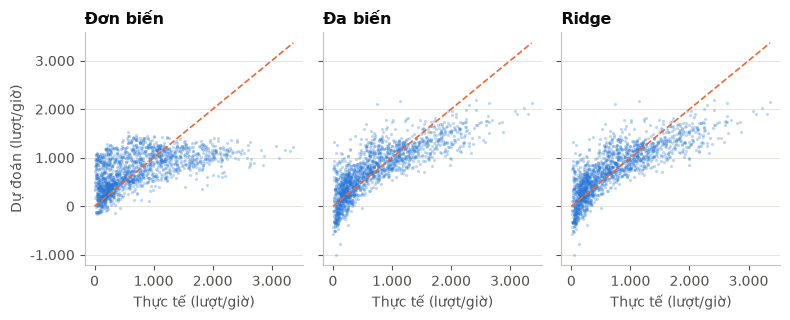

In [41]:
SHORT = ['Đơn biến', 'Đa biến', 'Ridge']
names = list(models)

def save_model_fig(fig, name):
    fig.savefig(MODEL_FIG / name, dpi=200, bbox_inches='tight', facecolor='white'); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(8, 3.3), sharex=True, sharey=True)
for a, k, t in zip(ax, names, SHORT):
    a.scatter(yte, preds[k], s=5, color=BLUE, alpha=.3, linewidths=0)
    a.plot([0, yte.max()], [0, yte.max()], color=ORANGE, ls='--', lw=1.2)
    a.set_title(t); a.set_xlabel('Thực tế (lượt/giờ)'); a.xaxis.set_major_formatter(THOUSANDS); a.yaxis.set_major_formatter(THOUSANDS)
ax[0].set_ylabel('Dự đoán (lượt/giờ)')
plt.tight_layout(); save_model_fig(fig, '10_thuc_te_vs_du_doan.png')

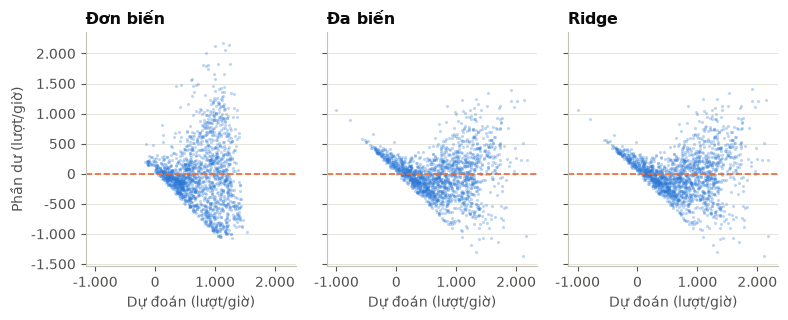

In [42]:
fig, ax = plt.subplots(1, 3, figsize=(8, 3.3), sharex=True, sharey=True)
for a, k, t in zip(ax, names, SHORT):
    a.scatter(preds[k], yte - preds[k], s=5, color=BLUE, alpha=.3, linewidths=0)
    a.axhline(0, color=ORANGE, ls='--', lw=1.2)
    a.set_title(t); a.set_xlabel('Dự đoán (lượt/giờ)'); a.xaxis.set_major_formatter(THOUSANDS); a.yaxis.set_major_formatter(THOUSANDS)
ax[0].set_ylabel('Phần dư (lượt/giờ)')
plt.tight_layout(); save_model_fig(fig, '11_residual_plot.png')

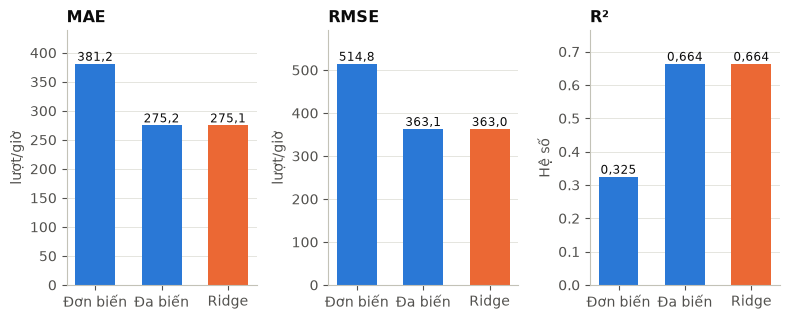

In [43]:
fig, ax = plt.subplots(1, 3, figsize=(8, 3.3))
for a, col, nd in zip(ax, ['MAE', 'RMSE', 'R²'], [1, 1, 3]):
    a.bar(range(3), res[col], color=[BLUE, BLUE, ORANGE], width=0.6); a.set_title(col)
    a.set_xticks(range(3)); a.set_xticklabels(SHORT); a.set_ylabel('Hệ số' if col == 'R²' else 'lượt/giờ')
    a.set_ylim(0, res[col].max() * 1.15)
    for i, v in enumerate(res[col]): a.text(i, v, vn_num(v, nd), ha='center', va='bottom', fontsize=8.5)
plt.tight_layout(); save_model_fig(fig, '12_so_sanh_mo_hinh.png')

### C.6 Mô hình tốt nhất và các hệ số lớn nhất của Ridge

In [44]:
print('Mô hình tốt nhất (RMSE thấp nhất):', res.loc[res['RMSE'].idxmin(), 'Mô hình'])
print(pd.Series(grid.best_estimator_[-1].coef_, X.columns).sort_values(key=abs, ascending=False).head(8).round(1))

Mô hình tốt nhất (RMSE thấp nhất): Ridge Regression
Humidity(%)                 -209.20
Dew point temperature(°C)    171.50
Hour_18                      159.20
Seasons_Winter              -154.00
Temperature(°C)              141.20
Hour_19                      104.40
Hour_8                       103.90
Hour_20                       87.60
dtype: float64
